In [1]:
print("OASIS INFOBYTE")
print("Task 1 - EDA on Retail Sales Data")
print("Project Started Successfully!")

OASIS INFOBYTE
Task 1 - EDA on Retail Sales Data
Project Started Successfully!


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("All Libraries Imported Successfully!")

All Libraries Imported Successfully!


In [4]:
print("Pandas Version:", pd.__version__)
print("NumPy Version:", np.__version__)
print("Matplotlib Version:", plt.matplotlib.__version__)
print("Seaborn Version:", sns.__version__)

Pandas Version: 3.1.1
NumPy Version: 2.5.4
Matplotlib Version: 3.11.2
Seaborn Version: 0.13.2


In [5]:
import pandas as pd

df = pd.read_csv("retail_sales_dataset.csv")

df.head()

,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100


In [6]:
# 1. how many rows and column are avaible in dataset
print("Dataset Shape:")
print(df.shape)

# 2. All column names
print("\nColumn Names:")
print(df.columns)

# 3. Data types and non-null values
print("\nDataset Information:")
df.info()

# 4. Missing values check
print("\nMissing Values:")
print(df.isnull().sum())

# 5. Duplicate records
print("\nDuplicate Rows:")
print(df.duplicated().sum())

Dataset Shape:
(1000, 9)

Column Names:
Index(['Transaction ID', 'Date', 'Customer ID', 'Gender', 'Age',
       'Product Category', 'Quantity', 'Price per Unit', 'Total Amount'],
      dtype='str')

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Transaction ID    1000 non-null   int64
 1   Date              1000 non-null   str  
 2   Customer ID       1000 non-null   str  
 3   Gender            1000 non-null   str  
 4   Age               1000 non-null   int64
 5   Product Category  1000 non-null   str  
 6   Quantity          1000 non-null   int64
 7   Price per Unit    1000 non-null   int64
 8   Total Amount      1000 non-null   int64
dtypes: int64(5), str(4)
memory usage: 70.4 KB

Missing Values:
Transaction ID      0
Date                0
Customer ID         0
Gender              0
Age                 0
Product Category 

In [7]:
# Numerical columns descriptive statistics
df.describe()


,Transaction ID,Age,Quantity,Price per Unit,Total Amount
count,1000.000000,1000.00000,1000.000000,1000.000000,1000.000000
mean,500.500000,41.39200,2.514000,179.890000,456.000000
std,288.819436,13.68143,1.132734,189.681356,559.997632
min,1.000000,18.00000,1.000000,25.000000,25.000000
25%,250.750000,29.00000,1.000000,30.000000,60.000000
50%,500.500000,42.00000,3.000000,50.000000,135.000000
75%,750.250000,53.00000,4.000000,300.000000,900.000000
max,1000.000000,64.00000,4.000000,500.000000,2000.000000


In [8]:
# Mean
print("Mean:")
print(df.mean(numeric_only=True))

# Median
print("\nMedian:")
print(df.median(numeric_only=True))

# Mode
print("\nMode:")
print(df.mode(numeric_only=True).iloc[0])

# Standard Deviation
print("\nStandard Deviation:")
print(df.std(numeric_only=True))

Mean:
Transaction ID    500.500
Age                41.392
Quantity            2.514
Price per Unit    179.890
Total Amount      456.000
dtype: float64

Median:
Transaction ID    500.5
Age                42.0
Quantity            3.0
Price per Unit     50.0
Total Amount      135.0
dtype: float64

Mode:
Transaction ID     1.0
Age               43.0
Quantity           4.0
Price per Unit    50.0
Total Amount      50.0
Name: 0, dtype: float64

Standard Deviation:
Transaction ID    288.819436
Age                13.681430
Quantity            1.132734
Price per Unit    189.681356
Total Amount      559.997632
dtype: float64


In [9]:
df['Date'] = pd.to_datetime(df['Date'])

print("Date column converted successfully!")

Date column converted successfully!


In [10]:
monthly_sales = df.groupby(
    df['Date'].dt.to_period('M')
)['Total Amount'].sum()

monthly_sales

Date
2023-01    35450
2023-02    44060
2023-03    28990
2023-04    33870
2023-05    53150
2023-06    36715
2023-07    35465
2023-08    36960
2023-09    23620
2023-10    46580
2023-11    34920
2023-12    44690
2024-01     1530
Freq: M, Name: Total Amount, dtype: int64

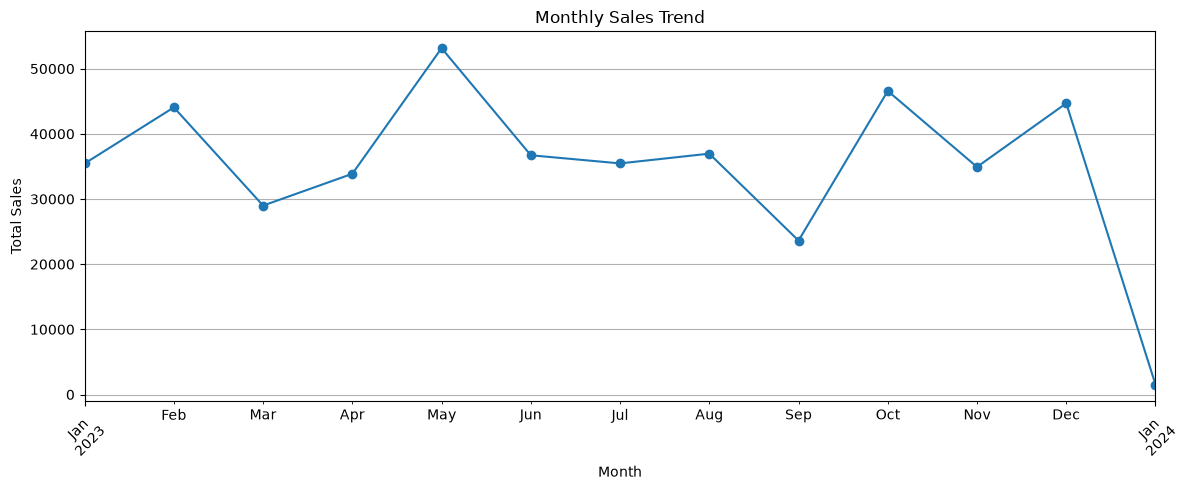

In [11]:
plt.figure(figsize=(12, 5))

monthly_sales.plot(kind='line', marker='o')

plt.title('Monthly Sales Trend')
plt.xlabel('Month')
plt.ylabel('Total Sales')
plt.xticks(rotation=45)

plt.grid(True)
plt.tight_layout()
plt.show()

### Monthly Sales Trend - Observation

The line chart shows the monthly sales performance.
It helps identify months with higher and lower sales.
This analysis helps businesses understand monthly sales patterns
and plan inventory and marketing activities.

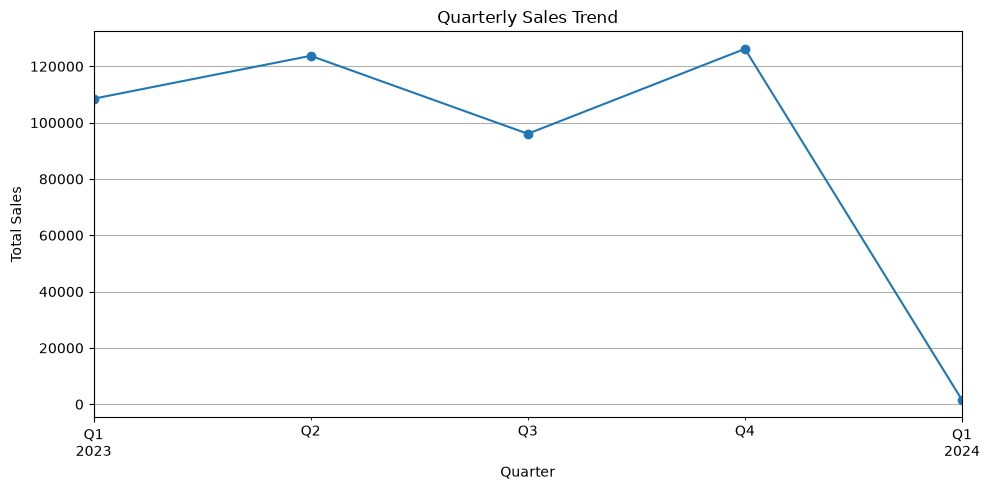

In [12]:
quarterly_sales = df.groupby(
    df['Date'].dt.to_period('Q')
)['Total Amount'].sum()

plt.figure(figsize=(10, 5))

quarterly_sales.plot(kind='line', marker='o')

plt.title('Quarterly Sales Trend')
plt.xlabel('Quarter')
plt.ylabel('Total Sales')

plt.grid(True)
plt.tight_layout()
plt.show()

In [13]:
# Create Age Groups
bins = [0, 18, 25, 35, 45, 55, 100]
labels = ['Below 18', '18-25', '26-35', '36-45', '46-55', 'Above 55']

df['Age Group'] = pd.cut(df['Age'], bins=bins, labels=labels)

# Count customers in each age group
age_counts = df['Age Group'].value_counts().sort_index()

print(age_counts)

Age Group
Below 18     21
18-25       148
26-35       205
36-45       202
46-55       229
Above 55    195
Name: count, dtype: int64


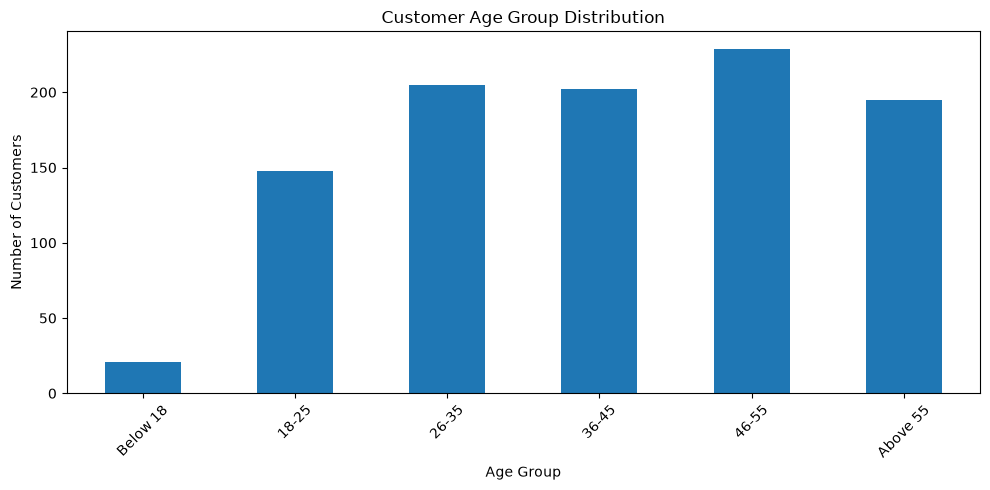

In [14]:
plt.figure(figsize=(10, 5))

age_counts.plot(kind='bar')

plt.title('Customer Age Group Distribution')
plt.xlabel('Age Group')
plt.ylabel('Number of Customers')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

### Customer Age Group - Observation

This chart shows the distribution of customers across different age groups.
It helps identify which age group contributes more to retail transactions.
Businesses can use this information to create targeted marketing campaigns.

In [15]:
gender_counts = df['Gender'].value_counts()

print(gender_counts)

Gender
Female    510
Male      490
Name: count, dtype: int64


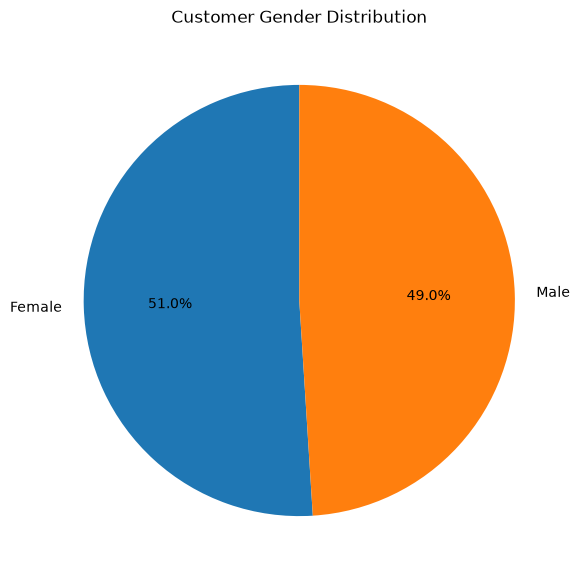

In [16]:
plt.figure(figsize=(7, 7))

plt.pie(
    gender_counts,
    labels=gender_counts.index,
    autopct='%1.1f%%',
    startangle=90
)

plt.title('Customer Gender Distribution')
plt.show()

In [17]:
category_revenue = df.groupby('Product Category')['Total Amount'].sum()

print(category_revenue)

Product Category
Beauty         143515
Clothing       155580
Electronics    156905
Name: Total Amount, dtype: int64


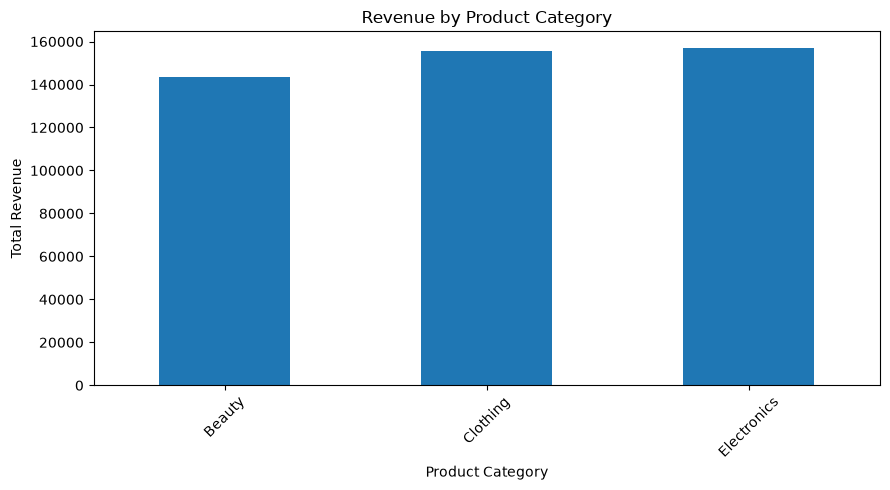

In [18]:
plt.figure(figsize=(9, 5))

category_revenue.plot(kind='bar')

plt.title('Revenue by Product Category')
plt.xlabel('Product Category')
plt.ylabel('Total Revenue')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [19]:
category_quantity = df.groupby('Product Category')['Quantity'].sum()

print("Product Category by Quantity:")
print(category_quantity.sort_values(ascending=False))

Product Category by Quantity:
Product Category
Clothing       894
Electronics    849
Beauty         771
Name: Quantity, dtype: int64


### Product Category Analysis - Observation

This analysis shows the revenue and quantity of products sold
across different categories.

It helps identify the best-performing product categories.
Businesses can focus on popular categories and improve their
inventory and marketing strategies.

In [20]:
# Select numerical columns
numeric_df = df.select_dtypes(include=['number'])

# Calculate correlation
correlation = numeric_df.corr()

print(correlation)

                Transaction ID       Age  Quantity  Price per Unit  \
Transaction ID        1.000000  0.065191 -0.026623       -0.060837   
Age                   0.065191  1.000000 -0.023737       -0.038423   
Quantity             -0.026623 -0.023737  1.000000        0.017501   
Price per Unit       -0.060837 -0.038423  0.017501        1.000000   
Total Amount         -0.075034 -0.060568  0.373707        0.851925   

                Total Amount  
Transaction ID     -0.075034  
Age                -0.060568  
Quantity            0.373707  
Price per Unit      0.851925  
Total Amount        1.000000  


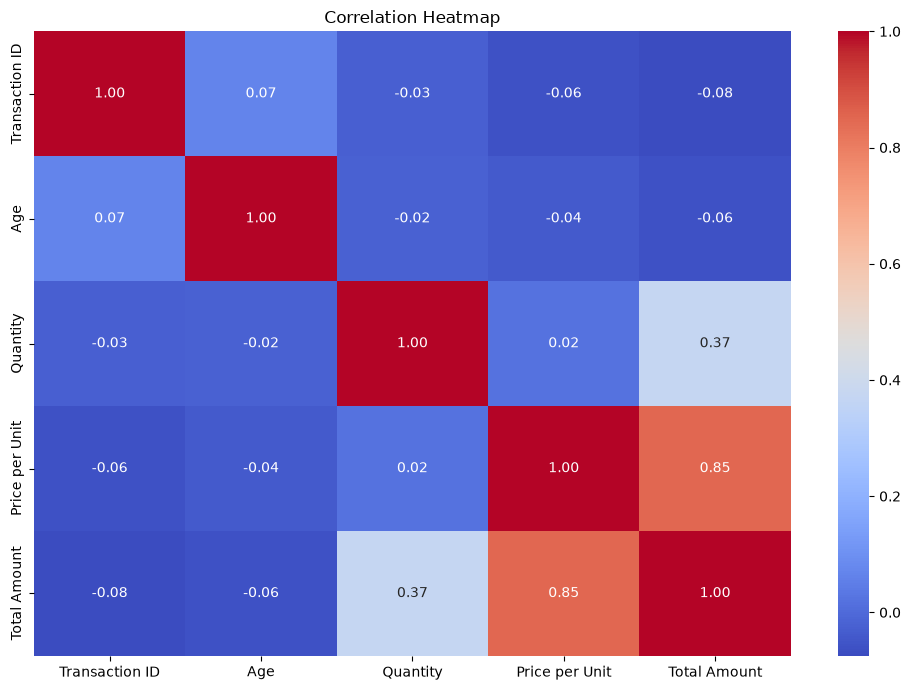

In [21]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap')
plt.tight_layout()
plt.show()

### Correlation Heatmap - Observation

The heatmap shows the correlation between numerical variables.
Positive values indicate that two variables tend to increase together,
while negative values indicate an opposite relationship.
This analysis helps understand relationships between sales,
quantity, age, and price.

In [22]:
gender_sales = df.groupby('Gender')['Total Amount'].sum()

print(gender_sales)

Gender
Female    232840
Male      223160
Name: Total Amount, dtype: int64


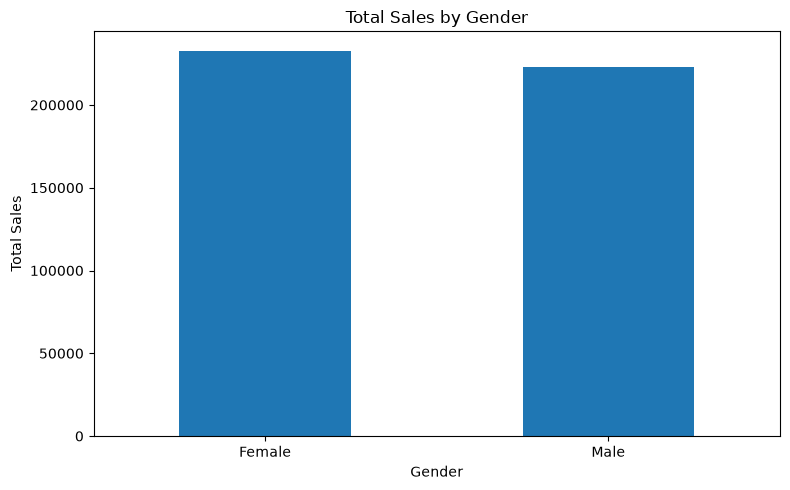

In [23]:
plt.figure(figsize=(8, 5))

gender_sales.plot(kind='bar')

plt.title('Total Sales by Gender')
plt.xlabel('Gender')
plt.ylabel('Total Sales')
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

### Sales by Gender - Observation

This chart compares total sales generated by male and female customers.
It helps identify which gender contributes more to overall revenue.
Businesses can use this information to improve customer-focused
marketing strategies.

# Conclusion

The Exploratory Data Analysis of the retail sales dataset helped
identify customer demographics, sales trends, and product category
performance.

## Business Recommendations

1. Focus on high-performing product categories to increase revenue.

2. Use monthly and quarterly sales trends to plan inventory and
   promotional campaigns.

3. Develop targeted marketing strategies based on customer age
   groups and gender distribution.

4. Monitor customer purchasing patterns to improve business decisions.

5. Maintain sufficient stock of popular product categories to
   avoid stock shortages.

Overall, data analysis helps businesses understand customer behaviour,
improve sales performance, and make better business decisions.

## Dataset Limitation

The selected retail sales dataset does not contain a Product Name
column. Therefore, individual top 10 best-selling products
could not be identified. Instead, product category-wise sales
and quantity analysis was performed.